<a href="https://colab.research.google.com/github/MohitSingh351/traffic-signal-ga/blob/main/Traffic_Signal_GA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🚦 Traffic Signal Timing Optimization Using Genetic Algorithms
### A Simulation-Based Comparative Study (Soft Computing project)

**Goal.** Choose the green-light duration of each road at a four-way intersection so that vehicles
wait as little as possible. A **Genetic Algorithm (GA)**, written from scratch with NumPy, searches
for the best green times. Each candidate is scored by running a **traffic simulation** on synthetic
traffic. The GA is compared with a conventional **Fixed-Equal** signal and with **Random Search**
given the same evaluation budget.

**How to run.** Nothing needs to be installed: the notebook
uses only NumPy, Pandas and Matplotlib, which Colab already provides. A full run takes about
2–3 minutes. Set `QUICK = True` in Section 12 for a faster demo run.

> **Scope.** All traffic is **synthetic** (randomly generated in Python), and the simulator is
> deliberately simple. This is not real traffic data, a real deployment or a real-time controller.
> The GA finds one good *fixed-time* plan for a given traffic pattern, offline.

## 1. Settings and constraints

**The intersection**
- **Phases.** There are four roads, N, S, E and W. Exactly **one road has green at a time**, in the
  fixed order N → S → E → W, and then the cycle repeats.
- **Lost time.** Every green is followed by **3 s amber** and **2 s all-red**, when no vehicle moves.
  That gives `L = 4 × 5 = 20 s` of lost time per cycle.
- **Saturation flow.** While its light is green, a queue discharges at **1800 vehicles/hour**, which is
  one vehicle every 2 s.

**Decision variables (the chromosome).** The four green times `[g_N, g_S, g_E, g_W]`, in whole seconds.

**Constraints**
- Each green: `10 ≤ g ≤ 60` s. Below 10 s is unsafe; above 60 s makes the other roads wait too long.
- Cycle length: `40 ≤ C = g_N + g_S + g_E + g_W + 20 ≤ 180` s. With 10 s minimum greens, the
  shortest cycle that can actually occur is 4·10 + 20 = 60 s.
- Together these mean the **sum of the greens** must lie in `[max(4·10, 40−20), min(4·60, 180−20)] = [40, 160]`.
  `validate_constraints()` computes this range and raises an error if the settings make it empty,
  i.e. if no valid plan could exist.

**Simulation timeline.** 300 s warm-up, then a 3600 s (1-hour) measurement window, then 600 s of drain.

**Seeds.** The GA and Random Search optimise on **train seeds 0–2** only. Every controller is
then evaluated on **20 unseen test seeds (1000–1019)**. This keeps the GA from simply memorising
the traffic it was trained on.

In [1]:
import math
import time
from collections import deque
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---- Intersection settings -------------------------------------------------------------
DIRECTIONS = ("N", "S", "E", "W")  # chromosome order and signal phase order
SAT_FLOW_VPH = 1800                # saturation flow: 1800 veh/h = one vehicle every 2 s of green
AMBER_S = 3                        # amber after every green (no departures)
ALL_RED_S = 2                      # all-red after every amber (no departures)
LOST_TIME_S = len(DIRECTIONS) * (AMBER_S + ALL_RED_S)  # 20 s lost per cycle

# ---- Timing constraints ----------------------------------------------------------------
G_MIN, G_MAX = 10, 60    # each green time (s)
C_MIN, C_MAX = 40, 180   # whole cycle = sum(greens) + LOST_TIME_S (s)

# ---- Simulation timeline (s) -------------------------------------------------------------
WARMUP_S = 300     # roads fill up; vehicles arriving now are NOT measured
MEASURE_S = 3600   # vehicles arriving in this 1-hour window are measured
DRAIN_S = 600      # extra time so measured vehicles can finish crossing

# ---- Random seeds (separate seeds for optimisation and for final testing) ---------------
TRAIN_SEEDS = [0, 1, 2]                # the GA / Random Search only ever see these
TEST_SEEDS = list(range(1000, 1020))   # 20 unseen traffic patterns for the final comparison
RUN_SEEDS = [0, 1, 2]                  # 3 independent GA / Random Search runs

# ---- GA defaults ---------------------------------------------------------------------------
GA_PARAMS = dict(pop_size=30, generations=40, p_crossover=0.8, p_mutation=0.2,
                 mutation_sigma=5.0, tournament_k=3, n_elites=2)


def validate_constraints(g_min=G_MIN, g_max=G_MAX, c_min=C_MIN, c_max=C_MAX, lost=LOST_TIME_S):
    """Return the allowed range (s_lo, s_hi) for the SUM of the four greens.

    Each green must be in [g_min, g_max] and the cycle in [c_min, c_max], so the green sum must be
    in [max(4*g_min, c_min - lost), min(4*g_max, c_max - lost)]. If that range is empty, no
    valid signal plan exists and we stop immediately with an error.
    """
    if not (0 < g_min <= g_max):
        raise ValueError(f"need 0 < g_min <= g_max, got {g_min}, {g_max}")
    s_lo = max(4 * g_min, c_min - lost)
    s_hi = min(4 * g_max, c_max - lost)
    if s_lo > s_hi:
        raise ValueError(f"impossible constraints: green sum must be in [{s_lo}, {s_hi}]")
    return s_lo, s_hi


S_LO, S_HI = validate_constraints()  # 40 and 160 with the defaults
print(f"Each green in [{G_MIN}, {G_MAX}] s; sum of greens in [{S_LO}, {S_HI}] s "
      f"(cycle {S_LO + LOST_TIME_S}-{S_HI + LOST_TIME_S} s); lost time {LOST_TIME_S} s per cycle")

Each green in [10, 60] s; sum of greens in [40, 160] s (cycle 60-180 s); lost time 20 s per cycle


## 2. Traffic scenarios

Arrival rates are given in vehicles per hour, in the order N, S, E, W.

**Y = Σ (arrival rate ÷ saturation flow)** measures how "full" the intersection is. A fixed-time
signal can only keep up if `Y < 1 − L/C`. With the longest allowed cycle (180 s), that means **Y < 0.889**.
All three scenarios are below this limit, so a well-chosen plan can serve them.

In [ ]:
# Arrival rates in vehicles per hour, in the order N, S, E, W.
SCENARIOS = {
    "Light":    {"rates": (150, 150, 150, 150), "description": "low traffic on all four roads"},
    "Moderate": {"rates": (300, 300, 250, 250), "description": "medium traffic, N-S slightly busier"},
    "Uneven":   {"rates": (550, 200, 150, 150), "description": "North road much busier than the others"},
}


def flow_ratio(rates):
    """Y = sum(arrival rate / saturation flow). A fixed signal can only keep up if Y < 1 - L/C."""
    return sum(r / SAT_FLOW_VPH for r in rates)


scenario_table = pd.DataFrame(
    [{"scenario": name, **dict(zip(DIRECTIONS, s["rates"])), "total_veh_per_h": sum(s["rates"]),
      "Y": round(flow_ratio(s["rates"]), 3), "description": s["description"]}
     for name, s in SCENARIOS.items()]
)
print(f"Stability limit for the longest allowed cycle: Y < {1 - LOST_TIME_S / C_MAX:.3f}")
scenario_table

Stability limit for the longest allowed cycle: Y < 0.889


,scenario,N,S,E,W,total_veh_per_h,Y,description
0,Light,150,150,150,150,600,0.333,low traffic on all four roads
1,Moderate,300,300,250,250,1100,0.611,"medium traffic, N-S slightly busier"
2,Uneven,550,200,150,150,1050,0.583,North road much busier than the others


## 3. Synthetic traffic generation

In every second, the number of vehicles arriving on each road is drawn from a **Poisson
distribution** with mean `rate / 3600`. Poisson arrivals are the standard model for random,
independent vehicle arrivals.

Every traffic pattern is created from a **seed**, so the same seed always gives exactly the same
vehicles. This is what makes the comparison fair: every controller is tested on identical traffic.

In [ ]:
def generate_arrivals(rates, seed, total_s=WARMUP_S + MEASURE_S + DRAIN_S):
    """Synthetic traffic: number of vehicles arriving on each road in every second.

    Arrivals are Poisson with mean rate/3600 per second. The same seed always gives the same
    traffic, so every controller can be tested on exactly the same vehicles.
    Returns an int array of shape (total_s, 4).
    """
    if len(rates) != 4 or any(r < 0 for r in rates):
        raise ValueError("rates must be four non-negative numbers (veh/h)")
    rng = np.random.default_rng(seed)
    per_second = np.asarray(rates, dtype=float) / 3600.0
    return rng.poisson(per_second, size=(total_s, 4))


def make_arrival_sets(rates, seeds, **kwargs):
    return [generate_arrivals(rates, s, **kwargs) for s in seeds]

Quick check: the generated rates should be close to the target rates (they differ slightly because the arrivals are random).

In [ ]:
total_s = WARMUP_S + MEASURE_S + DRAIN_S
check = []
for name, sc in SCENARIOS.items():
    a = generate_arrivals(sc["rates"], seed=0)
    measured = a.sum(axis=0) / total_s * 3600
    check.append({"scenario": name, **{f"target_{d}": r for d, r in zip(DIRECTIONS, sc["rates"])},
                  **{f"generated_{d}": round(m) for d, m in zip(DIRECTIONS, measured)}})
pd.DataFrame(check)

,scenario,target_N,target_S,target_E,target_W,generated_N,generated_S,generated_E,generated_W
0,Light,150,150,150,150,163,146,155,154
1,Moderate,300,300,250,250,311,315,240,241
2,Uneven,550,200,150,150,552,212,146,141


## 4. Constraint handling: the repair operator

Crossover and mutation can create invalid plans, for example a green of 7 s or a cycle longer than
180 s. Instead of throwing such plans away, every new plan passes through **`repair()`**:

1. **Round and clip.** Round each gene to whole seconds and clip it to `[10, 60]`.
2. **Sum too large** (cycle too long). Remove the extra seconds in proportion to each gene's
   *slack* (`g − 10`).
3. **Sum too small.** Add the missing seconds in proportion to each gene's *headroom* (`60 − g`).
4. **Leftover seconds.** Hand out any leftover single seconds by the *largest-remainder* rule, so the
   result is exact and deterministic.

**Why this always works.** Whenever the sum is too large, the genes have enough slack to absorb
the excess, and whenever it is too small they have enough headroom to absorb the deficit.
`validate_constraints()` guarantees both. The function ends with `assert is_valid(plan)`, and the
fitness function also asserts validity, so **an invalid plan can never be evaluated**.

In [ ]:
def is_valid(greens):
    """True if a plan satisfies every constraint: 4 integers, each in [G_MIN, G_MAX], sum in [S_LO, S_HI]."""
    return (len(greens) == 4
            and all(float(g).is_integer() and G_MIN <= g <= G_MAX for g in greens)
            and S_LO <= sum(greens) <= S_HI)


def _shift(values, room, amount, sign):
    """Move `amount` seconds out of (sign=-1) or into (sign=+1) the genes, proportional to `room`.

    Leftover single seconds go to the genes with the largest remainders (ties: lowest index),
    so the result is exact, deterministic, and never exceeds any gene's room.
    """
    total_room = sum(room)
    base = [amount * r // total_room for r in room]
    remainders = [amount * r % total_room for r in room]
    leftover = amount - sum(base)
    for i in sorted(range(4), key=lambda i: (-remainders[i], i))[:leftover]:
        base[i] += 1
    return [v + sign * b for v, b in zip(values, base)]


def repair(greens):
    """Turn ANY four numbers into a valid plan (constraint handling).

    1. Round each gene to whole seconds and clip it to [G_MIN, G_MAX].
    2. If the sum is above S_HI, remove the excess in proportion to each gene's slack (g - G_MIN).
       If it is below S_LO, add the deficit in proportion to each gene's headroom (G_MAX - g).
    This always succeeds: total slack >= excess because S_HI >= 4*G_MIN, and total headroom >=
    deficit because S_LO <= 4*G_MAX (guaranteed by validate_constraints).
    """
    if len(greens) != 4:
        raise ValueError("a plan needs exactly four green times")
    g = [min(max(math.floor(float(x) + 0.5), G_MIN), G_MAX) for x in greens]
    total = sum(g)
    if total > S_HI:
        g = _shift(g, [x - G_MIN for x in g], total - S_HI, sign=-1)
    elif total < S_LO:
        g = _shift(g, [G_MAX - x for x in g], S_LO - total, sign=+1)
    plan = tuple(int(x) for x in g)
    assert is_valid(plan), (greens, plan)
    return plan


def cycle_length(greens):
    return sum(greens) + LOST_TIME_S


def green_schedule(greens):
    """For each second of one cycle, which roads have green: list of [bool]*4.

    Phase order N -> S -> E -> W; each green is followed by amber and all-red (nobody moves).
    """
    schedule = []
    for i, g in enumerate(greens):
        for _ in range(g):
            schedule.append([j == i for j in range(4)])
        schedule.extend([[False] * 4] * (AMBER_S + ALL_RED_S))
    return schedule

In [ ]:
for raw in ([5, 80, 30, 30], [60, 60, 60, 60], [3.7, 0, -10, 12], [25, 25, 25, 25]):
    plan = repair(raw)
    print(f"{str(raw):22s} -> {plan}  sum={sum(plan):3d}  cycle={cycle_length(plan):3d} s  valid={is_valid(plan)}")

[5, 80, 30, 30]        -> (10, 60, 30, 30)  sum=130  cycle=150 s  valid=True
[60, 60, 60, 60]       -> (40, 40, 40, 40)  sum=160  cycle=180 s  valid=True
[3.7, 0, -10, 12]      -> (10, 10, 10, 12)  sum= 42  cycle= 62 s  valid=True
[25, 25, 25, 25]       -> (25, 25, 25, 25)  sum=100  cycle=120 s  valid=True


## 5. Traffic simulator

The simulator is a **queue simulation with 1-second steps**. Each road has a first-in-first-out
queue. Every second, for each road, three things happen:

1. Arriving vehicles join the back of the queue.
2. If the road has green, it earns 0.5 "departure credit" (1800 veh/h). Each full credit lets the
   front vehicle leave, so one vehicle leaves every 2 s of green.
3. The queue length is recorded.

**What is measured**
- **Average waiting time** (the main metric, in seconds per vehicle).
  - Only vehicles that **arrive during the 1-hour measurement window** are measured.
  - Warm-up vehicles are skipped, because the simulation starts with empty roads, which is
    unrealistic.
  - A vehicle's waiting time is `departure second − arrival second`. It is tracked into the drain
    period if needed.
  - **Censored vehicles.** A measured vehicle still waiting at the very end is counted with the
    time it has waited so far, and reported in `n_censored`. A non-zero value means the plan
    cannot keep up with demand.
- **Vehicles served:** vehicles that crossed the stop line during the 1-hour window.
- **Average queue length:** vehicles waiting on all roads, averaged over the window.

**Assumptions and limitations**
- **Point queues.** Vehicles wait "at" the stop line; the physical length of the queue is ignored.
- One lane group per road, with **no turning movements**, pedestrians or vehicle types.
- Constant saturation flow, with no start-up delay beyond the credit rule. No interaction with
  neighbouring intersections.
- Arrivals are Poisson with a **constant** average rate (no rush-hour peaks).
- The waiting time is therefore a *simulated stop-line waiting time*. It is useful for comparing
  plans, but it is not the official delay measure used in traffic engineering manuals.

In [ ]:
def simulate(arrivals, greens, warmup_s=WARMUP_S, measure_s=MEASURE_S, drain_s=DRAIN_S):
    """Simulate one fixed-time signal plan on one traffic pattern, second by second.

    Every second, for each road: (1) arriving vehicles join the back of the queue;
    (2) if the road has green it earns 0.5 'departure credit' (1800 veh/h) and every full credit
    lets the front vehicle leave; (3) the queue length is recorded.

    Measured vehicles are those ARRIVING inside the measurement window. Each one's waiting time
    is departure second - arrival second, even if it leaves during the drain period. A measured
    vehicle still waiting at the very end is 'censored' and counted with the time waited so far.
    """
    if not is_valid(greens):
        raise ValueError(f"invalid plan {greens}; use repair() first")
    total_s = warmup_s + measure_s + drain_s
    if arrivals.shape != (total_s, 4):
        raise ValueError(f"arrivals must have shape ({total_s}, 4), got {arrivals.shape}")
    sat_per_s = SAT_FLOW_VPH / 3600.0
    w_start, w_end = warmup_s, warmup_s + measure_s
    schedule = green_schedule(greens)
    cycle = len(schedule)
    arr = arrivals.tolist()

    queues = [deque() for _ in range(4)]  # each entry = arrival second of a waiting vehicle
    credit = [0.0] * 4
    waits = [[] for _ in range(4)]        # waiting times of measured vehicles, per road
    arrived, departed = [0] * 4, [0] * 4
    served_in_window = 0
    queue_sum = 0

    for t in range(total_s):
        green_now = schedule[t % cycle]
        in_window = w_start <= t < w_end
        for i in range(4):
            q = queues[i]
            n_new = arr[t][i]
            if n_new:
                arrived[i] += n_new
                q.extend([t] * n_new)
            if green_now[i]:
                c = credit[i] + sat_per_s
                while c >= 1.0 and q:
                    t_arr = q.popleft()
                    c -= 1.0
                    departed[i] += 1
                    if in_window:
                        served_in_window += 1
                    if w_start <= t_arr < w_end:
                        waits[i].append(t - t_arr)
                # an empty queue cannot 'bank' more than one vehicle's worth of credit
                credit[i] = c if q else min(c, 1.0)
            else:
                credit[i] = 0.0
            if in_window:
                queue_sum += len(q)

    n_censored = 0
    for i in range(4):
        for t_arr in queues[i]:
            if w_start <= t_arr < w_end:
                waits[i].append(total_s - t_arr)
                n_censored += 1

    all_waits = [w for road in waits for w in road]
    n = len(all_waits)
    result = {
        "avg_wait": sum(all_waits) / n if n else 0.0,  # MAIN METRIC (s per vehicle)
        "vehicles_measured": n,
        "n_censored": n_censored,
        "vehicles_served": served_in_window,           # departures during the 1-hour window
        "avg_queue": queue_sum / measure_s,            # vehicles waiting (all roads), time average
        "max_wait": max(all_waits) if n else 0,
    }
    for d, road in zip(DIRECTIONS, waits):
        result[f"avg_wait_{d}"] = sum(road) / len(road) if road else 0.0
    result["arrived"] = arrived
    result["departed"] = departed
    result["final_queue"] = [len(q) for q in queues]
    return result

Example: the Fixed-Equal plan (25 s each) on one Uneven traffic pattern. North receives 550 veh/h but 25 s of green can serve only about 360 veh/h, so its queue keeps growing.

In [ ]:
example = simulate(generate_arrivals(SCENARIOS["Uneven"]["rates"], seed=0), (25, 25, 25, 25))
{k: (round(v, 2) if isinstance(v, float) else v) for k, v in example.items()}

{'avg_wait': 467.83,
 'vehicles_measured': 1058,
 'n_censored': 150,
 'vehicles_served': 861,
 'avg_queue': 107.72,
 'max_wait': 1471,
 'avg_wait_N': 852.12,
 'avg_wait_S': 47.23,
 'avg_wait_E': 45.84,
 'avg_wait_W': 42.21,
 'arrived': [690, 265, 183, 176],
 'departed': [450, 264, 181, 171],
 'final_queue': [240, 1, 2, 5]}

## 6. Fitness function

**Fitness of a plan = its average waiting time, averaged over the 3 training traffic patterns.
Lower is better, so the GA *minimises* fitness.** The same definition is used everywhere: in the GA,
in Random Search, and for the Fixed-Equal train value.

Averaging over three patterns makes the fitness less dependent on one lucky or unlucky random draw.

`CachedFitness` remembers every plan it has already scored. A repeated plan is not simulated again,
and `unique_evals` counts how many *different* plans were really simulated. That count is the fair
budget used for Random Search.

In [ ]:
class CachedFitness:
    """Wraps an objective plan -> float (lower is better) and remembers every plan it has scored.

    unique_evals counts DIFFERENT plans actually simulated; it is the fair 'budget' used to
    compare the GA with Random Search. A cache hit returns the same value without simulating.
    """

    def __init__(self, objective):
        self.objective = objective
        self.cache = {}
        self.calls = 0

    @property
    def unique_evals(self):
        return len(self.cache)

    def __call__(self, greens):
        plan = tuple(int(g) for g in greens)
        assert is_valid(plan), f"invalid plan reached the fitness function: {plan}"
        self.calls += 1
        if plan not in self.cache:
            self.cache[plan] = float(self.objective(plan))
        return self.cache[plan]


def traffic_fitness(train_sets):
    """Fitness of a plan = average waiting time (s/veh) averaged over the TRAINING traffic patterns."""
    def objective(plan):
        return float(np.mean([simulate(a, plan)["avg_wait"] for a in train_sets]))
    return CachedFitness(objective)

## 7. Controllers

- **Fixed-Equal (baseline):** every road gets 25 s of green, giving a 120 s cycle. This is the
  conventional, untuned signal that the GA must beat. Without a baseline, we could not tell whether
  the GA's plan is actually good.
- **Random plan:** four uniform random numbers in `[10, 60]`, repaired. This is used both for the
  GA's first population and for Random Search, so both start from the same kind of plans.

In [ ]:
def fixed_equal_plan():
    """Conventional baseline: the same green for every road (25 s each, cycle 120 s)."""
    return repair([25, 25, 25, 25])


def random_plan(rng):
    """A random valid plan: four uniform values in [G_MIN, G_MAX], then repaired."""
    return repair(rng.uniform(G_MIN, G_MAX, size=4))

## 8. Genetic Algorithm (from scratch)

| GA concept | In this project |
|---|---|
| **Gene** | One green time, e.g. `g_N = 34` s |
| **Chromosome / individual** | One signal plan `[g_N, g_S, g_E, g_W]` |
| **Population** | 30 plans |
| **Fitness** | Average waiting time on the training traffic (minimise) |
| **Selection** | **Tournament** (k = 3): pick 3 plans at random; the one with the lowest waiting time becomes a parent |
| **Crossover** | **Uniform**, probability 0.8: each gene is copied from either parent with probability ½; the second child gets the other parent's gene |
| **Mutation** | Each gene, with probability 0.2, gets a random change drawn from Normal(0, 5 s) |
| **Constraint handling** | `repair()` after initialisation, crossover and mutation |
| **Elitism** | The 2 best plans are copied unchanged into the next generation, so the best solution is never lost |
| **Termination** | 40 generations |
| **History** | Best, mean and worst fitness of every generation |

**One generation:** evaluate everyone → keep the 2 elites → repeat (select 2 parents by tournament
→ crossover → mutate → repair) until there are 30 plans again.

**Why a GA here?** The waiting time comes from a random simulation, so there is no formula or
gradient to optimise. The search space is large: 51⁴ ≈ 6.8 million plans, each costing a simulation.
A GA needs only fitness values, and it combines good partial solutions (crossover) with small local
changes (mutation).

In [ ]:
def tournament_select(population, fitnesses, k, rng):
    """Pick k different individuals at random; the one with the LOWEST waiting time wins."""
    contenders = rng.choice(len(population), size=k, replace=False)
    winner = min(contenders, key=lambda i: fitnesses[i])
    return population[winner]


def uniform_crossover(parent1, parent2, rng):
    """Each gene of child 1 comes from parent 1 or parent 2 with probability 1/2 (child 2 gets the other)."""
    mask = rng.random(4) < 0.5
    child1 = [a if m else b for a, b, m in zip(parent1, parent2, mask)]
    child2 = [b if m else a for a, b, m in zip(parent1, parent2, mask)]
    return repair(child1), repair(child2)


def mutate(individual, p_mutation, sigma, rng):
    """Each gene, with probability p_mutation, gets a random change ~ Normal(0, sigma) seconds."""
    genes = [g + rng.normal(0.0, sigma) if rng.random() < p_mutation else g for g in individual]
    return repair(genes)


def run_ga(fitness, pop_size=30, generations=40, p_crossover=0.8, p_mutation=0.2,
           mutation_sigma=5.0, tournament_k=3, n_elites=2, seed=0, verbose=False):
    """Genetic Algorithm that MINIMISES fitness (average waiting time).

    Returns the best plan, its fitness and a per-generation history table.
    """
    if not (2 <= tournament_k <= pop_size and 0 <= n_elites < pop_size):
        raise ValueError("need 2 <= tournament_k <= pop_size and 0 <= n_elites < pop_size")
    rng = np.random.default_rng(seed)
    population = [random_plan(rng) for _ in range(pop_size)]
    best_plan, best_fit = None, math.inf
    history = []

    for gen in range(generations + 1):  # generation 0 is the random initial population
        fitnesses = [fitness(ind) for ind in population]
        i_best = int(np.argmin(fitnesses))
        if fitnesses[i_best] < best_fit:
            best_plan, best_fit = population[i_best], fitnesses[i_best]
        history.append({"generation": gen, "best": fitnesses[i_best], "mean": float(np.mean(fitnesses)),
                        "worst": max(fitnesses), "best_so_far": best_fit,
                        "unique_evals": getattr(fitness, "unique_evals", None)})
        if verbose:
            print(f"gen {gen:3d}  best {fitnesses[i_best]:8.2f}  mean {np.mean(fitnesses):8.2f}")
        if gen == generations:
            break

        # elitism: the best n_elites individuals survive unchanged
        order = np.argsort(fitnesses)
        next_pop = [population[i] for i in order[:n_elites]]
        while len(next_pop) < pop_size:
            p1 = tournament_select(population, fitnesses, tournament_k, rng)
            p2 = tournament_select(population, fitnesses, tournament_k, rng)
            if rng.random() < p_crossover:
                c1, c2 = uniform_crossover(p1, p2, rng)
            else:
                c1, c2 = p1, p2
            next_pop.append(mutate(c1, p_mutation, mutation_sigma, rng))
            next_pop.append(mutate(c2, p_mutation, mutation_sigma, rng))
        population = next_pop[:pop_size]

    return {"best_plan": best_plan, "best_fitness": best_fit, "history": pd.DataFrame(history)}

**Try it:** a short GA run on the Uneven scenario, printing every generation.

In [ ]:
demo_fitness = traffic_fitness(make_arrival_sets(SCENARIOS["Uneven"]["rates"], TRAIN_SEEDS))
demo = run_ga(demo_fitness, **{**GA_PARAMS, "generations": 15}, seed=0, verbose=True)
print("best plan:", demo["best_plan"], f"-> {demo['best_fitness']:.2f} s/veh,",
      demo_fitness.unique_evals, "different plans simulated")

gen   0  best    48.32  mean   586.47


gen   1  best    46.23  mean   317.31


gen   2  best    46.23  mean   145.48


gen   3  best    42.11  mean    81.64
gen   4  best    42.11  mean    52.31


gen   5  best    41.61  mean    49.54
gen   6  best    41.15  mean    47.61


gen   7  best    40.74  mean    47.36


gen   8  best    40.64  mean    45.47
gen   9  best    40.14  mean    43.94


gen  10  best    39.33  mean    42.21


gen  11  best    38.89  mean    43.12
gen  12  best    38.89  mean    41.15


gen  13  best    38.89  mean    42.21
gen  14  best    38.89  mean    41.86
gen  15  best    38.89  mean    42.40


best plan: (36, 14, 10, 10) -> 38.89 s/veh, 305 different plans simulated


## 9. Random Search (comparison with the same budget)

Random Search evaluates *different* random valid plans and keeps the best one. It is given exactly
the **same number of unique evaluations** that the GA used in the run with the same seed.

If the GA beats Random Search, the improvement comes from the GA's selection, crossover and mutation,
not just from trying many plans.

In [ ]:
def run_random_search(fitness, budget, seed=0, max_tries=100_000):
    """Evaluate `budget` DIFFERENT random valid plans and keep the best one."""
    rng = np.random.default_rng(seed)
    best_plan, best_fit = None, math.inf
    tries = 0
    while fitness.unique_evals < budget and tries < max_tries:
        tries += 1
        plan = random_plan(rng)
        if plan in fitness.cache:
            continue  # already tried: draw again so every evaluation is a new plan
        f = fitness(plan)
        if f < best_fit:
            best_plan, best_fit = plan, f
    return {"best_plan": best_plan, "best_fitness": best_fit}

## 10. Self-checks

These quick tests confirm that the building blocks behave correctly before the experiments run.
The same checks, and more, are in `tests/test_traffic_ga.py`, which can be run with `pytest`.

In [ ]:
rng = np.random.default_rng(0)
# 1. repair always produces a valid plan, even from extreme inputs
assert all(is_valid(repair(rng.uniform(-100, 300, 4))) for _ in range(5000))
assert repair((34, 12, 10, 10)) == (34, 12, 10, 10)          # valid plans are left unchanged
# 2. impossible settings are rejected
try:
    validate_constraints(g_min=50)
    raise AssertionError("should have failed")
except ValueError:
    pass
# 3. simulator: no vehicle is lost, and zero traffic gives zero waiting
a = generate_arrivals(SCENARIOS["Moderate"]["rates"], seed=5)
r = simulate(a, (30, 30, 25, 25))
assert all(r["arrived"][i] == r["departed"][i] + r["final_queue"][i] for i in range(4))
assert simulate(np.zeros_like(a), (25, 25, 25, 25))["avg_wait"] == 0
# 4. hand-worked case: car on N at t=0 leaves at t=1 (1 s); car on S at t=0 waits for S's green -> 16 s
tiny = np.zeros((70, 4), dtype=int); tiny[0, 0] = tiny[0, 1] = 1
r = simulate(tiny, (10, 10, 10, 10), warmup_s=0, measure_s=10, drain_s=60)
assert (r["avg_wait_N"], r["avg_wait_S"]) == (1, 16)
# 5. same seed -> same traffic -> same result
assert simulate(generate_arrivals((300, 300, 250, 250), 9), (30, 30, 25, 25)) == \
       simulate(generate_arrivals((300, 300, 250, 250), 9), (30, 30, 25, 25))
# 6. fitness is the mean over the train seeds, and the cache does not change it
sets = make_arrival_sets((300, 300, 250, 250), [0, 1])
fit = traffic_fitness(sets)
assert abs(fit((30, 30, 25, 25)) - np.mean([simulate(s, (30, 30, 25, 25))["avg_wait"] for s in sets])) < 1e-9
assert fit((30, 30, 25, 25)) == fit((30, 30, 25, 25)) and fit.unique_evals == 1
# 7. the GA finds a known optimum on a toy problem, and its best-so-far never gets worse (elitism)
toy = run_ga(CachedFitness(lambda p: float(np.abs(np.array(p) - [37, 14, 22, 11]).sum())), generations=60, seed=1)
assert toy["best_plan"] == (37, 14, 22, 11)
assert (np.diff(toy["history"]["best_so_far"]) <= 0).all()
print("All self-checks passed ✔")

All self-checks passed ✔


## 11. Experiment and plotting functions

**`run_comparison()`** does the following for each scenario:
1. Build the 3 training traffic patterns and the 20 test traffic patterns.
2. Score the Fixed-Equal plan.
3. Run the GA 3 times (seeds 0, 1, 2). After each GA run, run Random Search with the same seed and
   **the same number of unique evaluations**.
4. Simulate every resulting plan on the **same 20 unseen test patterns**.

**`summarize()`** builds the results table. GA and Random Search are first averaged over their
3 runs for each test seed. The table then reports the **mean and standard deviation over the 20 test
seeds**, plus the improvement over Fixed-Equal.

In [ ]:
def evaluate_on_test(plan, test_sets, test_seeds):
    """Simulate a plan on every unseen test traffic pattern; one row per test seed."""
    rows = []
    for seed, arrivals in zip(test_seeds, test_sets):
        r = simulate(arrivals, plan)
        rows.append({"test_seed": seed, **{k: v for k, v in r.items()
                                           if k not in ("arrived", "departed", "final_queue")}})
    return pd.DataFrame(rows)


def plan_columns(plan):
    return {f"g_{d}": g for d, g in zip(DIRECTIONS, plan)} | {"cycle": cycle_length(plan)}


def run_comparison(scenarios=SCENARIOS, test_seeds=TEST_SEEDS, run_seeds=RUN_SEEDS,
                   ga_params=GA_PARAMS, verbose=True):
    """Experiment 1 + 2: Fixed-Equal vs Random Search vs GA on every scenario.

    For each scenario: GA and Random Search are optimised on the TRAIN seeds (3 runs each,
    Random Search gets the same number of unique evaluations as the GA run with the same seed),
    then every plan is evaluated on the same unseen TEST seeds.
    Returns (test_results, runs, ga_histories) as DataFrames.
    """
    test_rows, runs, histories = [], [], []
    for name, sc in scenarios.items():
        t0 = time.perf_counter()
        train_sets = make_arrival_sets(sc["rates"], TRAIN_SEEDS)
        test_sets = make_arrival_sets(sc["rates"], test_seeds)

        def record(controller, run, plan, train_fit, n_evals):
            res = evaluate_on_test(plan, test_sets, test_seeds)
            test_rows.append(res.assign(scenario=name, controller=controller, run=run, **plan_columns(plan)))
            runs.append({"scenario": name, "controller": controller, "run": run, **plan_columns(plan),
                         "train_fitness": train_fit, "test_avg_wait": res["avg_wait"].mean(),
                         "unique_evals": n_evals})

        fixed = fixed_equal_plan()
        record("Fixed-Equal", 0, fixed, traffic_fitness(train_sets)(fixed), 0)
        for run in run_seeds:
            ga_fit = traffic_fitness(train_sets)
            ga = run_ga(ga_fit, seed=run, **ga_params)
            histories.append(ga["history"].assign(scenario=name, run=run))
            rs_fit = traffic_fitness(train_sets)
            rs = run_random_search(rs_fit, budget=ga_fit.unique_evals, seed=run)
            record("Random Search", run, rs["best_plan"], rs["best_fitness"], rs_fit.unique_evals)
            record("GA", run, ga["best_plan"], ga["best_fitness"], ga_fit.unique_evals)
            if verbose:
                print(f"  {name:8s} run {run}: GA {ga['best_plan']} train {ga['best_fitness']:.2f} | "
                      f"RS {rs['best_plan']} train {rs['best_fitness']:.2f} | "
                      f"{ga_fit.unique_evals} unique evaluations each")
        if verbose:
            print(f"{name}: done in {time.perf_counter() - t0:.1f} s")
    return pd.concat(test_rows, ignore_index=True), pd.DataFrame(runs), pd.concat(histories, ignore_index=True)


CONTROLLERS = ["Fixed-Equal", "Random Search", "GA"]


def summarize(test_results):
    """Results table: mean and std over the test seeds (GA / RS runs are averaged per seed first)."""
    metrics = ["avg_wait", "vehicles_served", "avg_queue", "n_censored"]
    per_seed = test_results.groupby(["scenario", "controller", "test_seed"])[metrics].mean().reset_index()
    table = per_seed.groupby(["scenario", "controller"])[metrics].agg(["mean", "std"])
    table.columns = [f"{m}_{s}" for m, s in table.columns]
    table = table.reset_index()
    fixed = table[table.controller == "Fixed-Equal"].set_index("scenario")["avg_wait_mean"]
    table["improvement_vs_fixed_%"] = [100 * (fixed[s] - w) / fixed[s]
                                       for s, w in zip(table.scenario, table.avg_wait_mean)]
    order = {c: i for i, c in enumerate(CONTROLLERS)}
    scen_order = {s: i for i, s in enumerate(SCENARIOS)}
    table = table.sort_values(by=["scenario", "controller"],
                              key=lambda col: col.map(scen_order if col.name == "scenario" else order))
    return table.reset_index(drop=True)


def run_mutation_experiment(scenario="Uneven", p_values=(0.05, 0.2, 0.5), test_seeds=TEST_SEEDS,
                            run_seeds=RUN_SEEDS, ga_params=GA_PARAMS, verbose=True):
    """Optional Experiment 3: effect of the mutation probability on the GA (one scenario)."""
    rates = SCENARIOS[scenario]["rates"]
    train_sets = make_arrival_sets(rates, TRAIN_SEEDS)
    test_sets = make_arrival_sets(rates, test_seeds)
    rows, histories = [], []
    for p in p_values:
        for run in run_seeds:
            fit = traffic_fitness(train_sets)
            ga = run_ga(fit, seed=run, **{**ga_params, "p_mutation": p})
            test_wait = evaluate_on_test(ga["best_plan"], test_sets, test_seeds)["avg_wait"].mean()
            rows.append({"p_mutation": p, "run": run, **plan_columns(ga["best_plan"]),
                         "train_fitness": ga["best_fitness"], "test_avg_wait": test_wait,
                         "unique_evals": fit.unique_evals})
            histories.append(ga["history"].assign(p_mutation=p, run=run))
            if verbose:
                print(f"  p_mutation={p}: run {run} -> {ga['best_plan']} train {ga['best_fitness']:.2f} "
                      f"test {test_wait:.2f} ({fit.unique_evals} unique evaluations)")
    return pd.DataFrame(rows), pd.concat(histories, ignore_index=True)

In [ ]:
COLORS = {"Fixed-Equal": "#8c8c8c", "Random Search": "#dd8452", "GA": "#4c72b0"}


def log_axis(ax):
    """Log-scale y axis with plain-number tick labels (e.g. 40, 60, 100 instead of 4x10^1)."""
    from matplotlib.ticker import LogLocator, NullFormatter, ScalarFormatter
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 3, 4, 5, 6, 8)))
    ax.yaxis.set_major_formatter(ScalarFormatter())
    ax.yaxis.set_minor_formatter(NullFormatter())


def plot_wait_bars(summary, path=None):
    """Bar chart of average waiting time per scenario and controller (error bars = std over test seeds)."""
    fig, ax = plt.subplots(figsize=(8, 4.5))
    scen = list(SCENARIOS)
    x = np.arange(len(scen))
    width = 0.26
    for k, ctrl in enumerate(CONTROLLERS):
        s = summary[summary.controller == ctrl].set_index("scenario").reindex(scen)
        bars = ax.bar(x + (k - 1) * width, s["avg_wait_mean"], width, yerr=s["avg_wait_std"], capsize=3,
                      label=ctrl, color=COLORS[ctrl])
        ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
    ax.set_xticks(x, scen)
    log_axis(ax)
    ax.set_ylabel("Average waiting time (s/vehicle, log scale)")
    ax.set_xlabel("Traffic scenario")
    ax.set_title("Experiment 1: average waiting time on unseen test traffic\n(mean ± std over test seeds)")
    ax.legend(frameon=False)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150)
    return fig


def plot_convergence(histories, runs, path=None):
    """Best and mean fitness per generation (mean over GA runs) with Fixed-Equal and Random Search levels."""
    scen = list(SCENARIOS)
    fig, axes = plt.subplots(1, len(scen), figsize=(5 * len(scen), 4))
    for ax, name in zip(np.atleast_1d(axes), scen):
        h = histories[histories.scenario == name]
        g = h.groupby("generation")
        best_mean = g["best_so_far"].mean()
        ax.plot(best_mean.index, best_mean, color=COLORS["GA"], lw=2.5, label="GA best (mean of runs)")
        ax.fill_between(best_mean.index, g["best_so_far"].min(), g["best_so_far"].max(),
                        color=COLORS["GA"], alpha=0.2, label="GA best (range over runs)")
        ax.plot(best_mean.index, g["mean"].mean(), color="#4c72b0", ls=":", label="GA population mean")
        r = runs[runs.scenario == name]
        fixed = r[r.controller == "Fixed-Equal"]["train_fitness"].iloc[0]
        rs = r[r.controller == "Random Search"]["train_fitness"].mean()
        ax.axhline(fixed, color=COLORS["Fixed-Equal"], ls="--", label=f"Fixed-Equal ({fixed:.1f} s)")
        ax.axhline(rs, color=COLORS["Random Search"], ls="-.", label=f"Random Search, same budget ({rs:.1f} s)")
        log_axis(ax)
        ax.set_title(name)
        ax.set_xlabel("Generation")
        ax.set_ylabel("Fitness = avg waiting time on train traffic (s/veh)")
        ax.legend(frameon=False, fontsize=7)
    fig.suptitle("Experiment 2: GA convergence (lower is better)")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150)
    return fig


def plot_green_times(runs, path=None):
    """Green time of each road: Fixed-Equal vs the GA's best-on-train plan, per scenario."""
    scen = list(SCENARIOS)
    fig, axes = plt.subplots(1, len(scen), figsize=(4.2 * len(scen), 3.6), sharey=True)
    for ax, name in zip(np.atleast_1d(axes), scen):
        r = runs[runs.scenario == name]
        fixed = r[r.controller == "Fixed-Equal"].iloc[0]
        ga = r[r.controller == "GA"].sort_values("train_fitness").iloc[0]
        x = np.arange(4)
        for off, row, ctrl in ((-0.2, fixed, "Fixed-Equal"), (0.2, ga, "GA")):
            vals = [row[f"g_{d}"] for d in DIRECTIONS]
            bars = ax.bar(x + off, vals, 0.4, color=COLORS[ctrl], label=f"{ctrl} (cycle {int(row['cycle'])} s)")
            ax.bar_label(bars, fontsize=8)
        ax.set_xticks(x, DIRECTIONS)
        ax.set_title(f"{name}  {SCENARIOS[name]['rates']} veh/h")
        ax.set_xlabel("Road")
        ax.legend(frameon=False, fontsize=8, loc="upper right")
    np.atleast_1d(axes)[0].set_ylabel("Green time (s)")
    np.atleast_1d(axes)[0].set_ylim(0, G_MAX + 15)
    fig.suptitle("Optimised green-light durations (GA best run) vs Fixed-Equal")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150)
    return fig


def plot_mutation(mut_results, mut_histories, path=None):
    """Experiment 3: convergence and test waiting time for each mutation probability."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    for p, h in mut_histories.groupby("p_mutation"):
        best = h.groupby("generation")["best_so_far"].mean()
        ax1.plot(best.index, best, label=f"p_mutation = {p}")
    ax1.set_xlabel("Generation")
    ax1.set_ylabel("Best fitness, mean of runs (s/veh)")
    log_axis(ax1)
    ax1.set_title("Convergence")
    ax1.legend(frameon=False)
    agg = mut_results.groupby("p_mutation")[["train_fitness", "test_avg_wait"]].agg(["mean", "std"])
    x = np.arange(len(agg))
    for col, marker, label in (("train_fitness", "o", "train traffic"), ("test_avg_wait", "s", "test traffic")):
        ax2.errorbar(x, agg[(col, "mean")], yerr=agg[(col, "std")], marker=marker, capsize=4, label=label)
    ax2.set_xticks(x, [str(p) for p in agg.index])
    ax2.set_xlabel("Mutation probability per gene")
    ax2.set_ylabel("Average waiting time (s/veh)")
    ax2.set_title("Final result (mean ± std over runs)")
    ax2.legend(frameon=False)
    fig.suptitle("Experiment 3: effect of mutation probability (Uneven scenario)")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=150)
    return fig

## 12. Experiment 1: controller comparison

`QUICK = True` gives a fast demo run (5 test seeds, 15 generations). The numbers discussed in
Section 16 come from the **full run** (`QUICK = False`).

In [ ]:
QUICK = False

test_seeds = TEST_SEEDS[:5] if QUICK else TEST_SEEDS
ga_params = {**GA_PARAMS, "generations": 15} if QUICK else GA_PARAMS
results_dir, figures_dir = Path("results"), Path("figures")
results_dir.mkdir(exist_ok=True)
figures_dir.mkdir(exist_ok=True)

start = time.perf_counter()
test_results, runs, histories = run_comparison(test_seeds=test_seeds, ga_params=ga_params)
summary = summarize(test_results)
print(f"Experiment 1 finished in {time.perf_counter() - start:.0f} s")

test_results.to_csv(results_dir / "e1_test_results.csv", index=False)
runs.to_csv(results_dir / "e1_runs.csv", index=False)
summary.round(3).to_csv(results_dir / "e1_summary.csv", index=False)
histories.to_csv(results_dir / "e2_ga_history.csv", index=False)

  Light    run 0: GA (10, 11, 10, 10) train 25.25 | RS (13, 21, 14, 18) train 32.50 | 423 unique evaluations each


  Light    run 1: GA (10, 11, 10, 10) train 25.25 | RS (21, 18, 27, 14) train 36.71 | 373 unique evaluations each


  Light    run 2: GA (11, 10, 10, 10) train 25.37 | RS (23, 18, 19, 25) train 38.19 | 343 unique evaluations each
Light: done in 10.0 s


  Moderate run 0: GA (24, 24, 20, 20) train 50.49 | RS (29, 30, 31, 26) train 58.94 | 740 unique evaluations each


  Moderate run 1: GA (22, 26, 22, 20) train 50.75 | RS (22, 26, 19, 21) train 55.90 | 601 unique evaluations each


  Moderate run 2: GA (24, 24, 20, 20) train 50.49 | RS (21, 22, 22, 20) train 53.68 | 657 unique evaluations each
Moderate: done in 18.2 s


  Uneven   run 0: GA (34, 14, 12, 10) train 38.23 | RS (42, 21, 17, 16) train 45.35 | 477 unique evaluations each


  Uneven   run 1: GA (34, 14, 12, 10) train 38.23 | RS (38, 19, 15, 14) train 43.48 | 541 unique evaluations each


  Uneven   run 2: GA (38, 14, 12, 12) train 38.61 | RS (53, 24, 14, 19) train 46.23 | 690 unique evaluations each
Uneven: done in 15.6 s
Experiment 1 finished in 44 s


**Results table** (unseen test traffic, mean ± std over test seeds). Waiting time is in s/vehicle, vehicles served is per hour, queue is in vehicles.

In [ ]:
table = pd.DataFrame({
    "Scenario": summary["scenario"],
    "Controller": summary["controller"],
    "Avg waiting time (s)": [f"{m:.1f} ± {s:.1f}" for m, s in zip(summary.avg_wait_mean, summary.avg_wait_std)],
    "Vehicles served (/h)": summary["vehicles_served_mean"].round(0).astype(int),
    "Avg queue (veh)": summary["avg_queue_mean"].round(1),
    "Still waiting at end": summary["n_censored_mean"].round(1),
    "Improvement vs Fixed": [f"{x:.1f} %" for x in summary["improvement_vs_fixed_%"]],
})
table

,Scenario,Controller,Avg waiting time (s),Vehicles served (/h),Avg queue (veh),Still waiting at end,Improvement vs Fixed
0,Light,Fixed-Equal,43.0 ± 1.2,609,7.3,0.0,0.0 %
1,Light,Random Search,36.5 ± 0.8,609,6.2,0.0,15.2 %
2,Light,GA,26.5 ± 1.1,608,4.5,0.0,38.3 %
3,Moderate,Fixed-Equal,53.6 ± 3.7,1105,16.5,0.0,0.0 %
4,Moderate,Random Search,53.2 ± 3.7,1105,16.3,0.0,0.7 %
5,Moderate,GA,48.5 ± 2.3,1107,14.9,0.0,9.5 %
6,Uneven,Fixed-Equal,506.9 ± 53.3,866,119.7,149.6,0.0 %
7,Uneven,Random Search,46.4 ± 2.9,1055,13.6,0.0,90.8 %
8,Uneven,GA,39.6 ± 2.6,1056,11.6,0.0,92.2 %


**Best plan found in each run** (the train fitness is what the optimiser saw; the test average is on unseen traffic):

In [ ]:
runs.round(2)

,scenario,controller,run,g_N,g_S,g_E,g_W,cycle,train_fitness,test_avg_wait,unique_evals
0,Light,Fixed-Equal,0,25,25,25,25,120,42.67,43.03,0
1,Light,Random Search,0,13,21,14,18,86,32.50,33.44,423
2,Light,GA,0,10,11,10,10,61,25.25,26.55,423
3,Light,Random Search,1,21,18,27,14,100,36.71,37.68,373
4,Light,GA,1,10,11,10,10,61,25.25,26.55,373
5,Light,Random Search,2,23,18,19,25,105,38.19,38.31,343
6,Light,GA,2,11,10,10,10,61,25.37,26.51,343
7,Moderate,Fixed-Equal,0,25,25,25,25,120,58.15,53.56,0
8,Moderate,Random Search,0,29,30,31,26,136,58.94,56.48,740
9,Moderate,GA,0,24,24,20,20,108,50.49,47.38,740


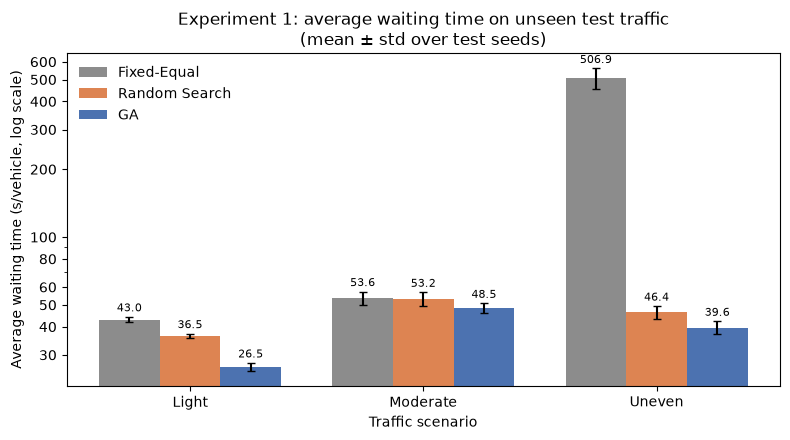

In [ ]:
fig = plot_wait_bars(summary, figures_dir / "e1_avg_wait_bars.png")
plt.show()

## 13. Experiment 2: GA convergence

- The **solid line** is the best fitness found so far in each generation, averaged over the 3 GA runs.
  The shaded band is the range across those runs.
- The **dotted line** is the population's mean fitness.
- The **dashed lines** show the Fixed-Equal plan and the result Random Search reached with the same budget.
- The y-axis is logarithmic, because early random plans can be very poor.

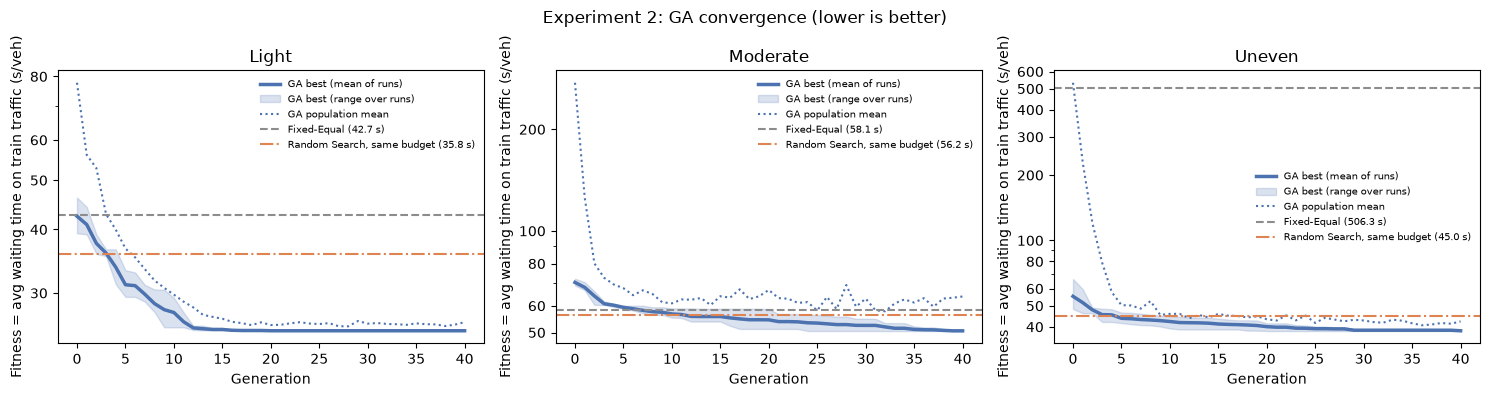

,best at generation 0,best at generation 10,best at final generation,Fixed-Equal (train)
scenario,,,,
Light,42.48,27.46,25.29,42.67
Moderate,70.38,56.75,50.58,58.15
Uneven,55.28,42.32,38.36,506.33


In [ ]:
fig = plot_convergence(histories, runs, figures_dir / "e2_convergence.png")
plt.show()

conv = histories.groupby(["scenario", "generation"])["best_so_far"].mean().unstack()
pd.DataFrame({
    "best at generation 0": conv[0].round(2),
    "best at generation 10": conv[min(10, conv.columns.max())].round(2),
    "best at final generation": conv[conv.columns.max()].round(2),
    "Fixed-Equal (train)": runs[runs.controller == "Fixed-Equal"].set_index("scenario")["train_fitness"].round(2),
}).loc[list(SCENARIOS)]

## 14. Optimised green-light durations

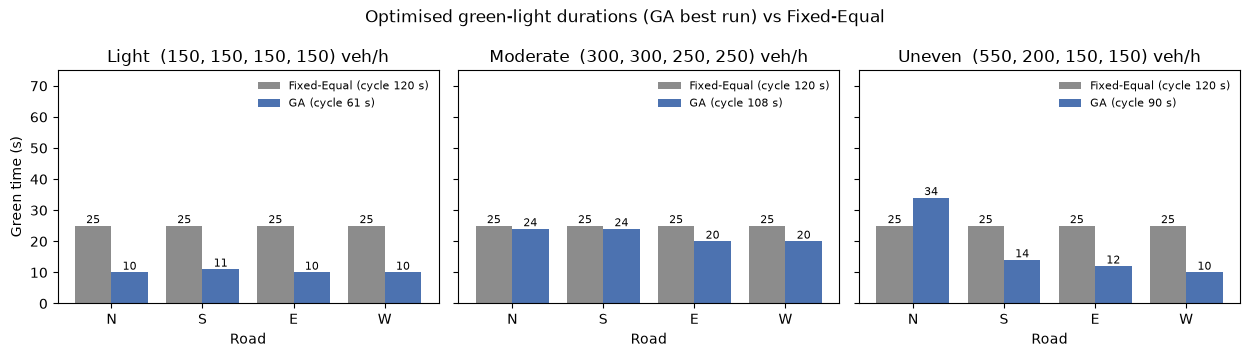

In [ ]:
fig = plot_green_times(runs, figures_dir / "green_times.png")
plt.show()

## 15. Experiment 3 (optional): effect of the mutation probability

The GA is run on the Uneven scenario with per-gene mutation probability 0.05, 0.2 (the default) and
0.5, 3 runs each, with everything else unchanged. `unique_evals` shows how many different plans each
run actually explored.

  p_mutation=0.05: run 0 -> (34, 14, 10, 12) train 38.87 test 39.78 (214 unique evaluations)


  p_mutation=0.05: run 1 -> (38, 14, 12, 12) train 38.61 test 39.64 (224 unique evaluations)


  p_mutation=0.05: run 2 -> (39, 16, 12, 12) train 39.13 test 40.69 (245 unique evaluations)


  p_mutation=0.2: run 0 -> (34, 14, 12, 10) train 38.23 test 39.65 (477 unique evaluations)


  p_mutation=0.2: run 1 -> (34, 14, 12, 10) train 38.23 test 39.65 (541 unique evaluations)


  p_mutation=0.2: run 2 -> (38, 14, 12, 12) train 38.61 test 39.64 (690 unique evaluations)


  p_mutation=0.5: run 0 -> (32, 14, 10, 10) train 38.41 test 39.57 (865 unique evaluations)


  p_mutation=0.5: run 1 -> (32, 14, 10, 10) train 38.41 test 39.57 (892 unique evaluations)


  p_mutation=0.5: run 2 -> (32, 14, 10, 10) train 38.41 test 39.57 (978 unique evaluations)


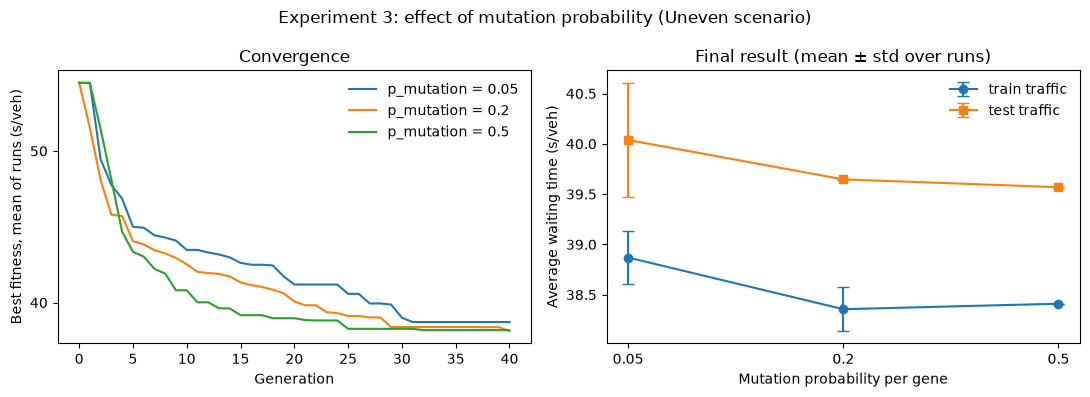

train_fitness       test_avg_wait       unique_evals        
                    mean   std          mean   std         mean     std
p_mutation                                                             
0.05               38.87  0.26         40.04  0.57       227.67   15.82
0.20               38.36  0.22         39.65  0.00       569.33  109.29
0.50               38.41  0.00         39.57  0.00       911.67   59.01

In [ ]:
mut_results, mut_histories = run_mutation_experiment(test_seeds=test_seeds, ga_params=ga_params)
mut_results.to_csv(results_dir / "e3_mutation.csv", index=False)
fig = plot_mutation(mut_results, mut_histories, figures_dir / "e3_mutation.png")
plt.show()
mut_results.groupby("p_mutation")[["train_fitness", "test_avg_wait", "unique_evals"]].agg(["mean", "std"]).round(2)

## 16. Observations, limitations and conclusion

*The numbers below come from the full run (`QUICK = False`). The code is deterministic, so
re-running the notebook reproduces them exactly.*

**Experiment 1: controller comparison** (average waiting time on 20 unseen test patterns)

| Scenario | Fixed-Equal | Random Search | GA | GA vs Fixed |
|---|---|---|---|---|
| Light | 43.0 s | 36.5 s | **26.5 s** | 38.3 % lower |
| Moderate | 53.6 s | 53.2 s | **48.5 s** | 9.5 % lower |
| Uneven | 506.9 s* | 46.4 s | **39.6 s** | 92.2 % lower |

- **Light traffic.** The GA chose the shortest possible greens, about 10 s each, giving a 61 s cycle.
  With little traffic, a short cycle means a vehicle waits less for its next green. Fixed-Equal's
  120 s cycle makes vehicles wait for no reason.
- **Moderate traffic.** The GA gave the busier N and S roads more green (24, 24, 20, 20) and
  reduced waiting by about 10 %. The gain is smaller here because the equal plan is already
  reasonable for nearly balanced traffic.
- **Uneven traffic.** \*Fixed-Equal cannot cope. With 25 s of green, North can serve only about
  360 veh/h, but 550 veh/h arrive.
  - North's queue grows all hour, and about 150 measured vehicles per test pattern are still
    waiting at the end.
  - Its 506.9 s is therefore a *lower bound* that would grow with a longer simulation.
  - The GA gives North a much longer green (34 s against 14/12/10 s) and serves about 1056
    vehicles/h instead of about 866.
- **Vehicles served** is almost the same for all controllers in Light and Moderate, because every
  plan can serve the demand there. The difference is in **how long** vehicles wait.
- **GA vs Random Search.** With the same number of evaluations, the GA was better in every
  scenario, so selection, crossover and mutation clearly help beyond random trial and error.

**Experiment 2: convergence.** Yes, the GA improves over successive generations.
- The best fitness drops quickly in the first ~10–15 generations and then levels off, and the
  3 independent runs end very close to each other.
- The population mean falls sharply too, as poor plans are replaced by better ones.
- In Light and Uneven, even the best *random* starting plan beats Fixed-Equal. In Moderate the GA
  passes the Fixed-Equal level after about 8 generations.
- The GA passes the Random Search result after about 4–12 generations, i.e. well before using its
  full budget, and keeps improving after that.

**Experiment 3: mutation probability.** The differences are small (under 0.5 s on test traffic),
so they should be read as trends:
- With **p = 0.05**, the population quickly fills with copies. The runs explored only about 230
  different plans, ended slightly worse and varied more between runs.
- With **p = 0.5**, the GA explored the most plans (about 900) and all 3 runs found the same plan.
- The default **0.2** sits in between.

**Advantages**
- The GA needs no formula or gradient, only a way to score a plan.
- It adapts the plan to the traffic pattern automatically.
- Constraints are always respected.
- It is easy to extend, for example by changing the fitness function.

**Limitations**
- Synthetic traffic and a simplified simulator (point queues, no turns, pedestrians or vehicle types).
- A single isolated intersection.
- Constant demand.
- The result is a fixed-time plan, not real-time control.
- The GA is stochastic, so it is run several times; more training patterns would reduce the risk
  of fitting the training traffic.

**Conclusion.** A from-scratch Genetic Algorithm, guided only by simulated waiting times, found
signal timings that reduced the average waiting time by about 10–92 % compared with an equal
fixed-time signal on unseen traffic. It also beat Random Search with the same budget. The largest
gains come where traffic is unbalanced, and those are exactly the situations where an equal split
is a poor choice.

**Future scope**
- Time-varying (rush-hour) demand.
- Several coordinated intersections.
- Comparison with Webster's classical formula.
- Calibration with real traffic counts.
- Adaptive control that re-optimises as traffic changes.